In [3]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pymannkendall as mk          # pip install pymannkendall

sys.path.append(str(Path.cwd()))
from utils import save_fig, DATA_DIR, FIGURES_DIR

pd.set_option('display.float_format', '{:.4f}'.format)

In [4]:
df = pd.read_csv(DATA_DIR / 'C_factor_mean_Belgorodskaya_Oblast.csv')

print(df.head())
print(df.dtypes)
print(f'Years: {df.year.min()}–{df.year.max()}, rows: {len(df)}')

   year  C_mean
0  2008  0.0615
1  2009  0.0886
2  2010  0.0885
3  2011  0.0513
4  2012  0.0475
year        int64
C_mean    float64
dtype: object
Years: 2008–2022, rows: 15


In [5]:
print(df['C_mean'].describe())

summary = pd.DataFrame({
    'value': [
        df['C_mean'].mean(),
        df['C_mean'].median(),
        df['C_mean'].std(),
        df['C_mean'].min(),
        df['C_mean'].max(),
        df.loc[df['C_mean'].idxmax(), 'year'],
        df.loc[df['C_mean'].idxmin(), 'year'],
    ]
}, index=['mean', 'median', 'std', 'min', 'max', 'year_max', 'year_min'])
print(summary)

count   15.0000
mean     0.0601
std      0.0152
min      0.0358
25%      0.0509
50%      0.0607
75%      0.0635
max      0.0886
Name: C_mean, dtype: float64
             value
mean        0.0601
median      0.0607
std         0.0152
min         0.0358
max         0.0886
year_max 2009.0000
year_min 2016.0000


Figure saved: C:\Users\Кирилл\Portfolio\project-rusle-c-factor\figures\c_factor_timeseries.png


WindowsPath('C:/Users/Кирилл/Portfolio/project-rusle-c-factor/figures/C_factor_timeseries.png')

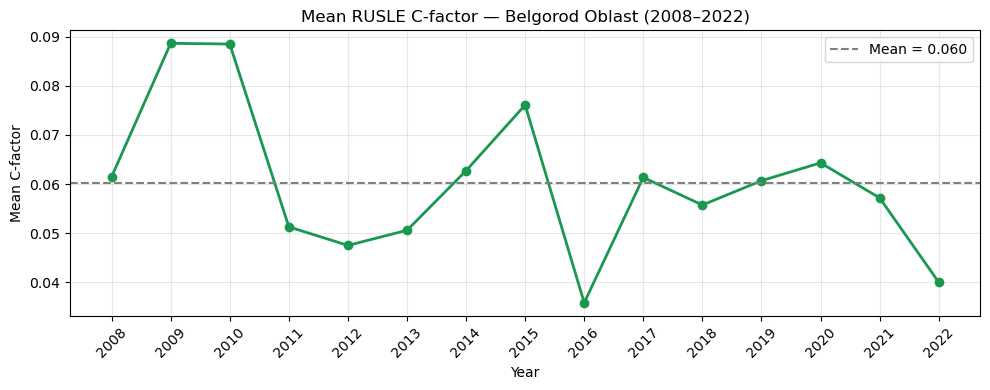

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df['year'], df['C_mean'], marker='o', linewidth=2, color='#1a9850')
ax.axhline(df['C_mean'].mean(), color='gray', linestyle='--',
           label=f"Mean = {df['C_mean'].mean():.3f}")
ax.set_xlabel('Year')
ax.set_ylabel('Mean C-factor')
ax.set_title('Mean RUSLE C-factor — Belgorod Oblast (2008–2022)')
ax.set_xticks(df['year'])
ax.tick_params(axis='x', rotation=45)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
save_fig(fig, 'C_factor_timeseries.png')

Figure saved: C:\Users\Кирилл\Portfolio\project-rusle-c-factor\figures\C_factor_histogram.png


WindowsPath('C:/Users/Кирилл/Portfolio/project-rusle-c-factor/figures/C_factor_histogram.png')

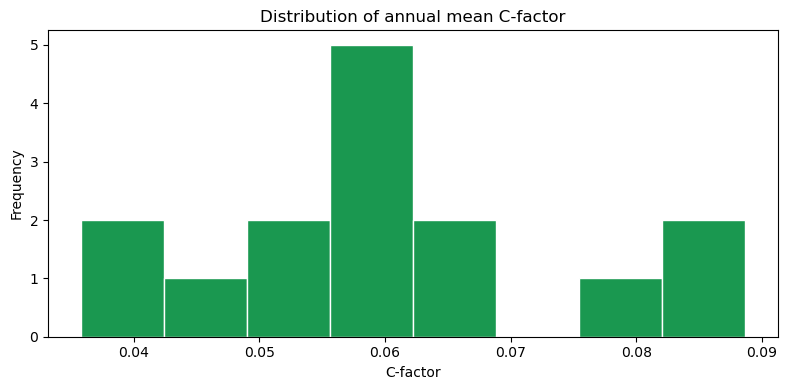

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['C_mean'], bins=8, color='#1a9850', edgecolor='white')
ax.set_xlabel('C-factor')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of annual mean C-factor')
plt.tight_layout()
save_fig(fig, 'C_factor_histogram.png')

Figure saved: C:\Users\Кирилл\Portfolio\project-rusle-c-factor\figures\C_factor_boxplot.png


WindowsPath('C:/Users/Кирилл/Portfolio/project-rusle-c-factor/figures/C_factor_boxplot.png')

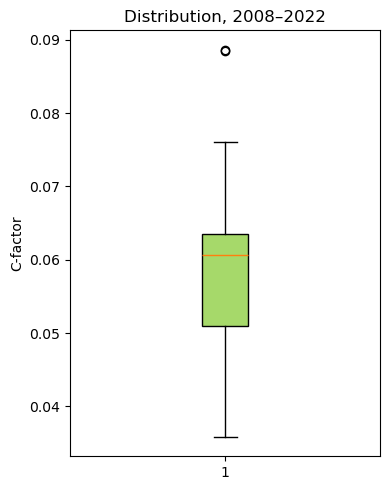

In [8]:
fig, ax = plt.subplots(figsize=(4, 5))
ax.boxplot(df['C_mean'], vert=True, patch_artist=True,
           boxprops=dict(facecolor='#a6d96a'))
ax.set_ylabel('C-factor')
ax.set_title('Distribution, 2008–2022')
plt.tight_layout()
save_fig(fig, 'C_factor_boxplot.png')

In [9]:
result = mk.original_test(df['C_mean'].values)

print(f"Trend:       {result.trend}")
print(f"Sen's slope: {result.slope:.6f} per year")
print(f"p-value:     {result.p:.4f}")
print(f"Tau:         {result.Tau:.4f}")
print(f"Z:           {result.z:.4f}")

Trend:       no trend
Sen's slope: -0.001036 per year
p-value:     0.2350
Tau:         -0.2381
Z:           -1.1877


Figure saved: C:\Users\Кирилл\Portfolio\project-rusle-c-factor\figures\C_factor_timeseries_smoothed.png


WindowsPath('C:/Users/Кирилл/Portfolio/project-rusle-c-factor/figures/C_factor_timeseries_smoothed.png')

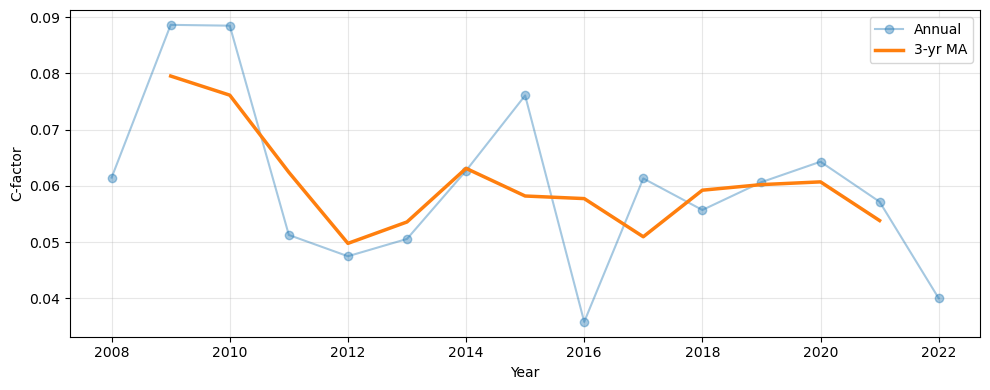

In [10]:
# Скользящее среднее 3 года 
df['C_mean_smooth'] = df['C_mean'].rolling(3, center=True).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df['year'], df['C_mean'], marker='o', alpha=0.4, label='Annual')
ax.plot(df['year'], df['C_mean_smooth'], linewidth=2.5, label='3-yr MA')
ax.set_xlabel('Year'); ax.set_ylabel('C-factor')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig(fig, 'C_factor_timeseries_smoothed.png')